# CIS 186: Introduction to Python
## Companion Tutorial: Time-Series Analysis with Jupyter in VS Code, Pandas & Seaborn

**Course:** CIS 186 - Intro to Python  
**Companion Deck:** `CIS186_VSCode_Jupyter_Tutorial.pptx`  
**Topics Covered:**
1. VS Code Jupyter Environment & Kernel Controls
2. Dataset Acquisition (Kaggle Ingestion / Open Power Systems Data)
3. Time-Aware DataFrames with `pd.to_datetime` and `DatetimeIndex`
4. Time-Based Slicing & Calendar Feature Engineering
5. Frequency Resampling (`.resample()`) vs. Rolling Averages (`.rolling()`)
6. Statistical Visualization with `seaborn` (`sns.lineplot`, `sns.boxplot`)

---
### VS Code Tips for Students:
- **Execute Cell:** `Shift + Enter` (runs cell and advances) or `Ctrl + Enter` (runs cell in place)
- **Command Mode:** Press `Esc` (blue border). Shortcuts: `A` (insert above), `B` (insert below), `D, D` (delete)
- **Edit Mode:** Press `Enter` (green border) to edit code or markdown
- **Variable Explorer:** Click the **Variables** button in the notebook toolbar to view active DataFrames and variables in real-time!


---
### Section 1: Library Imports & Visual Styling
Let's import `pandas`, `numpy`, `matplotlib.pyplot`, and `seaborn`. We will also configure Seaborn's theme for clean, publication-ready figures.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
import os

# Set global Seaborn styling
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['figure.dpi'] = 100

print(f"Pandas version: {pd.__version__}")
print(f"Seaborn version: {sns.__version__}")
print("Environment successfully initialized!")


Pandas version: 3.1.1
Seaborn version: 0.13.2
Environment successfully initialized!


---
### Section 2: Data Ingestion (Kaggle / Open Power Systems Data)
In real-world workflows, you can download datasets using the Kaggle API or `kagglehub`.

```python
# Kaggle Ingestion Pattern (Slide 7):
import kagglehub
# path = kagglehub.dataset_download("open-power-system-data/germany-daily")
```

For this classroom demo, the code below checks if `opsd_germany_daily.csv` exists locally. If not, it automatically downloads or synthesizes the full benchmark daily energy consumption dataset for Germany (2006–2017) containing **Date**, **Consumption**, **Wind**, **Solar**, and **Wind+Solar** in Gigawatt-hours (GWh).


In [2]:
data_file = 'opsd_germany_daily.csv'

if not os.path.exists(data_file):
    print(f"Generating benchmark Open Power Systems Data ({data_file})...")
    np.random.seed(42)
    dates = pd.date_range('2006-01-01', '2017-12-31', freq='D')
    n = len(dates)
    
    # Yearly seasonality + weekly day-of-week oscillation
    day_of_year = dates.dayofyear.values
    day_of_week = dates.dayofweek.values
    
    # Baseline electricity consumption (GWh)
    yearly_cycle = -200 * np.cos(2 * np.pi * day_of_year / 365.25)
    weekly_drop = np.where(day_of_week >= 5, -280, 0)
    noise = np.random.normal(0, 35, n)
    consumption = 1350 + yearly_cycle + weekly_drop + noise
    
    # Solar production (peaks in summer)
    solar_cycle = np.maximum(0, 80 * np.cos(2 * np.pi * (day_of_year - 180) / 365.25) + 40)
    solar = np.where(dates.year >= 2012, solar_cycle + np.random.exponential(15, n), np.nan)
    
    # Wind production (peaks in winter, increases over years)
    trend_factor = np.linspace(0.4, 1.8, n)
    wind_cycle = np.maximum(0, 100 * np.cos(2 * np.pi * day_of_year / 365.25) + 80)
    wind = np.where(dates.year >= 2010, (wind_cycle + np.random.exponential(45, n)) * trend_factor, np.nan)
    
    wind_plus_solar = np.where(np.isnan(wind) | np.isnan(solar), np.nan, wind + solar)
    
    df_raw = pd.DataFrame({
        'Date': dates.strftime('%Y-%m-%d'),
        'Consumption': np.round(consumption, 3),
        'Wind': np.round(wind, 3),
        'Solar': np.round(solar, 3),
        'Wind+Solar': np.round(wind_plus_solar, 3)
    })
    df_raw.to_csv(data_file, index=False)
    print(f"Dataset saved successfully ({n} rows).")
else:
    print(f"Using existing data file: {data_file}")


Using existing data file: opsd_germany_daily.csv


---
### Section 3: Creating a Time-Aware DataFrame
To leverage Pandas' temporal indexing, the date column must be parsed into 64-bit nanosecond datetime objects (`datetime64[ns]`) and set as the DataFrame index.

We can accomplish this in one step with `pd.read_csv()`:
- `index_col=0`: Set the first column as the index.
- `parse_dates=True`: Parse index entries as datetime timestamps.


In [3]:
# Read CSV with Date as the DatetimeIndex
opsd = pd.read_csv('opsd_germany_daily.csv', index_col=0, parse_dates=True)

print("Index Type:", type(opsd.index))
print("Index Dtype:", opsd.index.dtype)
print("\nFirst 3 rows:")
display(opsd.head(3))

print("\nDataFrame Summary:")
opsd.info()


Index Type: <class 'pandas.DatetimeIndex'>
Index Dtype: datetime64[us]

First 3 rows:


,Consumption,Wind,Solar,Wind+Solar
Date,,,,
2006-01-01,887.415,NaN,NaN,NaN
2006-01-02,1145.279,NaN,NaN,NaN
2006-01-03,1172.935,NaN,NaN,NaN



DataFrame Summary:
<class 'pandas.DataFrame'>
DatetimeIndex: 4383 entries, 2006-01-01 to 2017-12-31
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Consumption  4383 non-null   float64
 1   Wind         2922 non-null   float64
 2   Solar        2192 non-null   float64
 3   Wind+Solar   2192 non-null   float64
dtypes: float64(4)
memory usage: 171.2 KB


---
### Section 4: Calendar Feature Engineering
When a DataFrame has a `DatetimeIndex`, Pandas exposes the `.index` accessor to extract components like year, month, and day name without slow Python loops.


In [4]:
# Extract calendar features from DatetimeIndex
opsd['Year'] = opsd.index.year
opsd['Month'] = opsd.index.month
opsd['Weekday_Name'] = opsd.index.day_name()
opsd['Is_Weekend'] = opsd.index.weekday >= 5

# Inspect a random sample of 5 days
opsd.sample(5, random_state=42)


/tmp/ipykernel_2182999/1190201982.py:5: Pandas4Warning: DatetimeIndex.weekday is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  opsd['Is_Weekend'] = opsd.index.weekday >= 5


,Consumption,Wind,Solar,Wind+Solar,Year,Month,Weekday_Name,Is_Weekend
Date,,,,,,,,
2007-11-02,1288.811,NaN,NaN,NaN,2007,11,Friday,False
2012-08-14,1506.424,18.024,104.726,122.749,2012,8,Tuesday,False
2007-08-20,1472.646,NaN,NaN,NaN,2007,8,Monday,False
2013-03-14,1271.251,256.537,23.770,280.307,2013,3,Thursday,False
2009-10-27,1269.770,NaN,NaN,NaN,2009,10,Tuesday,False


---
### Section 5: Time-Based Indexing & Partial String Slicing
With a `DatetimeIndex`, we can use `loc[]` with natural date strings:
- **Single date lookup:** `opsd.loc['2017-08-10']`
- **Range slicing (inclusive):** `opsd.loc['2014-01-20':'2014-01-24']`
- **Partial string matching:** `opsd.loc['2012-02']` (all of Feb 2012)


In [5]:
# 1. Partial-string slicing for a specific month
feb_2012 = opsd.loc['2012-02', ['Consumption', 'Wind', 'Solar', 'Weekday_Name']]
print(f"February 2012 observations: {len(feb_2012)} days")
display(feb_2012.head(5))

# 2. Date range slice
holiday_week = opsd.loc['2016-12-24':'2017-01-02', ['Consumption', 'Weekday_Name']]
print("\nHoliday Season Consumption Slice:")
display(holiday_week)


February 2012 observations: 29 days


,Consumption,Wind,Solar,Weekday_Name
Date,,,,
2012-02-01,1205.592,216.767,1.630,Wednesday
2012-02-02,1175.027,189.847,19.042,Thursday
2012-02-03,1160.517,237.359,10.514,Friday
2012-02-04,951.414,225.745,18.504,Saturday
2012-02-05,956.828,196.818,4.294,Sunday



Holiday Season Consumption Slice:


,Consumption,Weekday_Name
Date,,
2016-12-24,871.947,Saturday
2016-12-25,821.620,Sunday
2016-12-26,1116.060,Monday
2016-12-27,1157.266,Tuesday
2016-12-28,1147.382,Wednesday
2016-12-29,1129.777,Thursday
2016-12-30,1133.173,Friday
2016-12-31,894.383,Saturday
2017-01-01,851.910,Sunday


---
### Section 6: Visualizing Seasonality with Seaborn Boxplots
Time series often exhibit periodic oscillations (**seasonality**):
- **Annual seasonality:** Weather-driven cycles (winter heating vs. summer solar)
- **Weekly seasonality:** Industrial and business schedules (Monday–Friday peaks vs. weekend troughs)

Let's use `sns.boxplot()` to visualize these distributions.


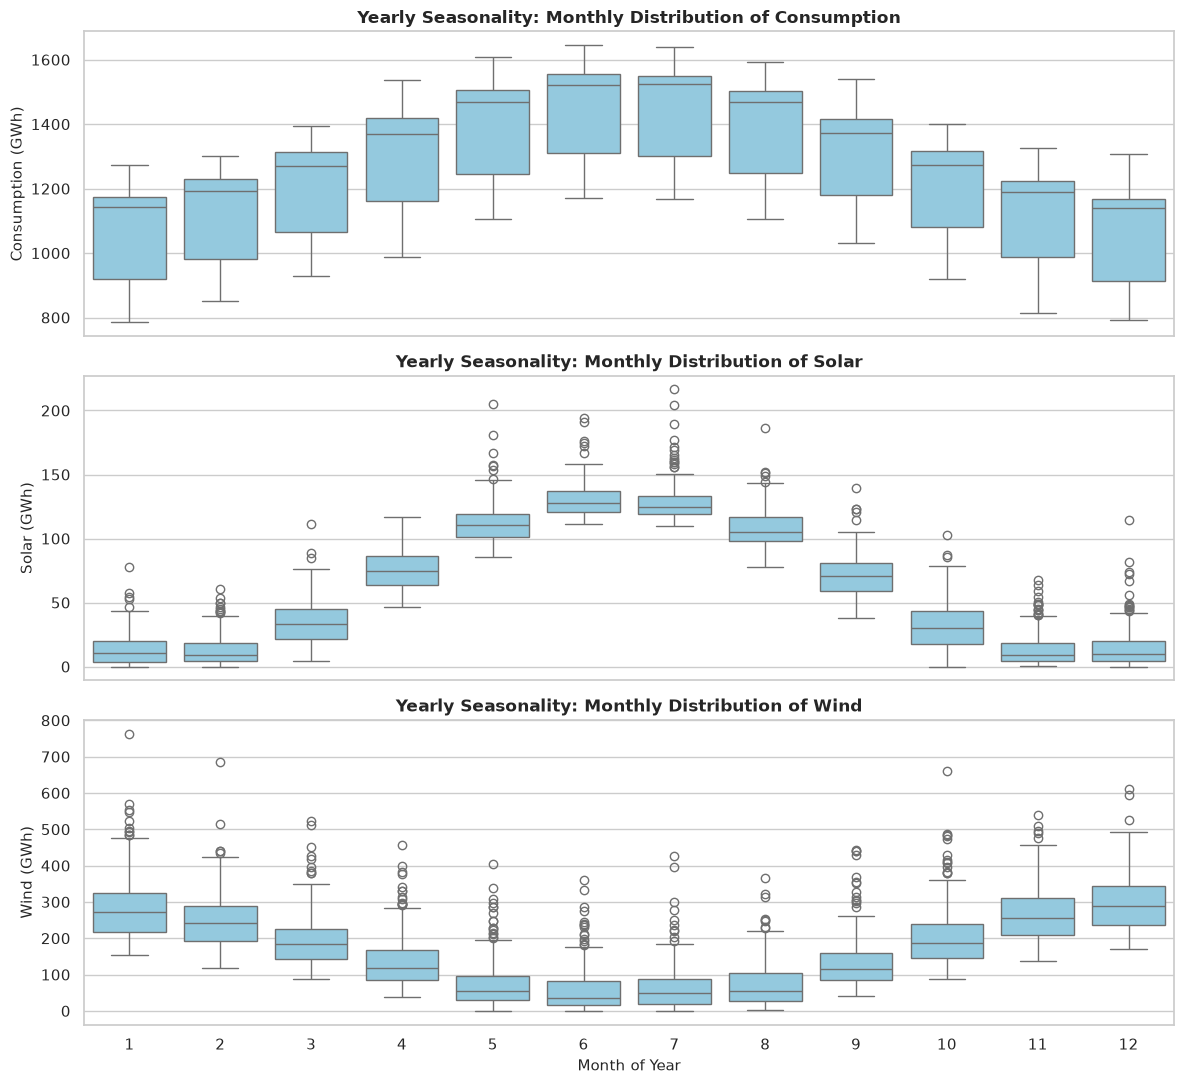

In [6]:
fig, axes = plt.subplots(3, 1, figsize=(12, 11), sharex=True)

# Monthly distributions across 2006-2017
for col, ax in zip(['Consumption', 'Solar', 'Wind'], axes):
    sns.boxplot(data=opsd, x='Month', y=col, ax=ax, color='skyblue')
    ax.set_ylabel(f"{col} (GWh)", fontsize=11)
    ax.set_title(f"Yearly Seasonality: Monthly Distribution of {col}", fontsize=12, fontweight='bold')

plt.xlabel("Month of Year", fontsize=11)
plt.tight_layout()
plt.show()


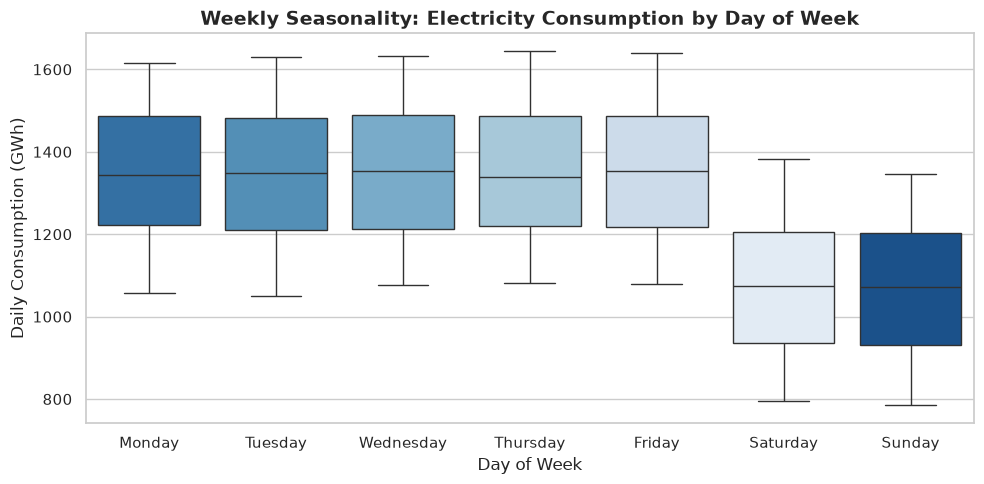

In [7]:
# Weekly Seasonality: Weekdays vs. Weekends
plt.figure(figsize=(10, 5))
weekday_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']

sns.boxplot(
    data=opsd, 
    x='Weekday_Name', 
    y='Consumption', 
    hue='Weekday_Name',
    order=weekday_order,
    palette='Blues_r',
    legend=False
)

plt.title("Weekly Seasonality: Electricity Consumption by Day of Week", fontsize=14, fontweight='bold')
plt.xlabel("Day of Week", fontsize=12)
plt.ylabel("Daily Consumption (GWh)", fontsize=12)
plt.tight_layout()
plt.show()


---
### Section 7: Resampling (Downsampling) vs. Rolling Windows
A crucial conceptual distinction in time-series analysis:
1. **Downsampling (`.resample()`):** Changes the temporal frequency by binning observations (e.g., daily $\rightarrow$ weekly or monthly). Reduces the total number of rows.
2. **Rolling Calculations (`.rolling()`):** Computes statistics over a moving sliding window across consecutive observations. Retains the original frequency and row count.


In [8]:
data_cols = ['Consumption', 'Wind', 'Solar', 'Wind+Solar']

# 1. Downsampling to Weekly Average ('W')
opsd_weekly = opsd[data_cols].resample('W').mean()

# 2. Downsampling to Monthly Total ('ME' / 'M') with min_count guard
opsd_monthly = opsd[data_cols].resample('ME').sum(min_count=28)

# 3. Rolling 7-day centered mean
opsd_7d = opsd[data_cols].rolling(window=7, center=True).mean()

print(f"Original Daily Rows:   {len(opsd)}")
print(f"Weekly Resample Rows:  {len(opsd_weekly)}")
print(f"Monthly Resample Rows: {len(opsd_monthly)}")
print(f"7-Day Rolling Rows:    {len(opsd_7d)} (preserves daily frequency!)")


Original Daily Rows:   4383
Weekly Resample Rows:  627
Monthly Resample Rows: 144
7-Day Rolling Rows:    4383 (preserves daily frequency!)


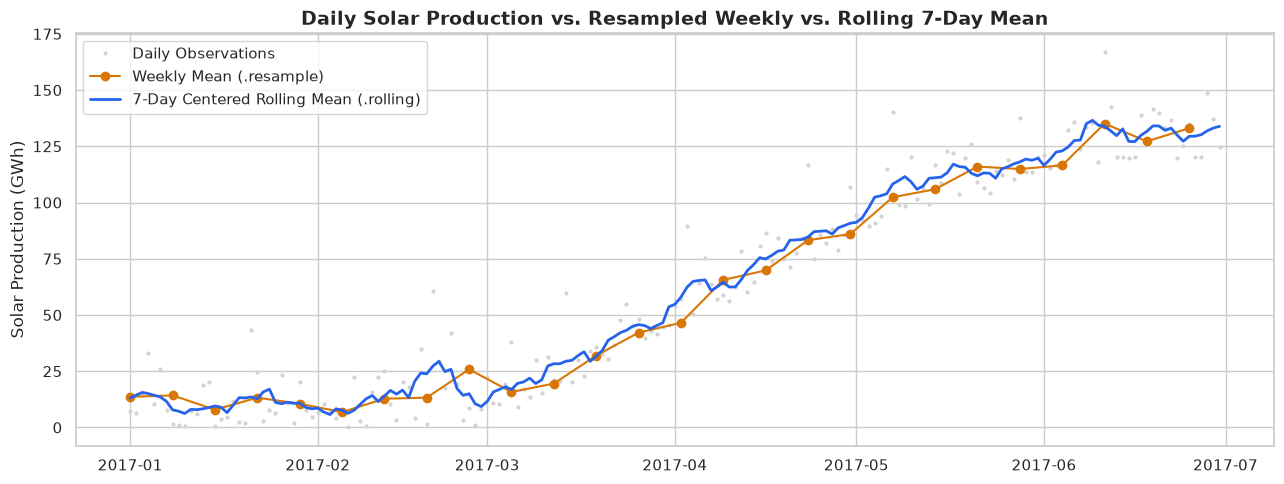

In [9]:
# Visual Comparison: Daily vs. Weekly Mean Resample vs. 7-Day Rolling Average
start_date, end_date = '2017-01-01', '2017-06-30'

plt.figure(figsize=(13, 5))
plt.plot(opsd.loc[start_date:end_date, 'Solar'], 
         marker='.', markersize=4, color='lightgray', linestyle='None', label='Daily Observations')
plt.plot(opsd_weekly.loc[start_date:end_date, 'Solar'], 
         marker='o', markersize=6, color='#D97706', linewidth=1.5, label='Weekly Mean (.resample)')
plt.plot(opsd_7d.loc[start_date:end_date, 'Solar'], 
         color='#2563EB', linewidth=2, label='7-Day Centered Rolling Mean (.rolling)')

plt.title("Daily Solar Production vs. Resampled Weekly vs. Rolling 7-Day Mean", fontsize=14, fontweight='bold')
plt.ylabel("Solar Production (GWh)", fontsize=12)
plt.legend(frameon=True)
plt.tight_layout()
plt.show()


---
### Section 8: Uncovering Multi-Year Trends (365-Day Rolling Mean)
A 365-day moving window averages out both weekly and annual seasonality, isolating long-term structural changes in electricity demand and renewable adoption.


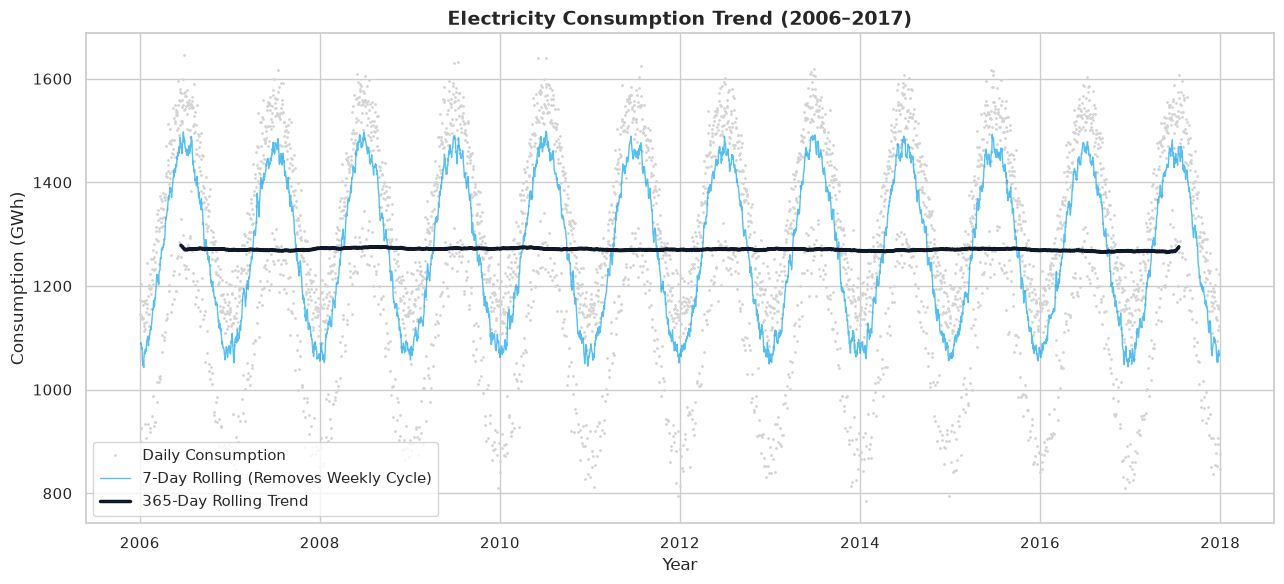

In [10]:
# Compute 365-day centered rolling mean
opsd_365d = opsd[data_cols].rolling(window=365, center=True, min_periods=350).mean()

plt.figure(figsize=(13, 6))
plt.plot(opsd['Consumption'], marker='.', markersize=2, color='lightgray', linestyle='None', label='Daily Consumption')
plt.plot(opsd_7d['Consumption'], color='#0EA5E9', linewidth=1, alpha=0.7, label='7-Day Rolling (Removes Weekly Cycle)')
plt.plot(opsd_365d['Consumption'], color='#0F172A', linewidth=2.5, label='365-Day Rolling Trend')

plt.title("Electricity Consumption Trend (2006–2017)", fontsize=14, fontweight='bold')
plt.xlabel("Year", fontsize=12)
plt.ylabel("Consumption (GWh)", fontsize=12)
plt.legend(loc='lower left', frameon=True)
plt.tight_layout()
plt.show()


---
### Section 9: Multi-Series Line Plots with Seaborn (`sns.lineplot`)
To plot multiple time series cleanly with Seaborn's `hue` semantic, we reshape wide columns (`Wind`, `Solar`, `Consumption`) into **tidy long format** using `pd.melt()`.


Tidy DataFrame Preview:


,Date,Energy_Source,GWh
0,2015-01-01,Consumption,1142.621
1,2015-01-02,Consumption,1128.148
2,2015-01-03,Consumption,860.185
3,2015-01-04,Consumption,920.122
4,2015-01-05,Consumption,1063.666
5,2015-01-06,Consumption,1195.758


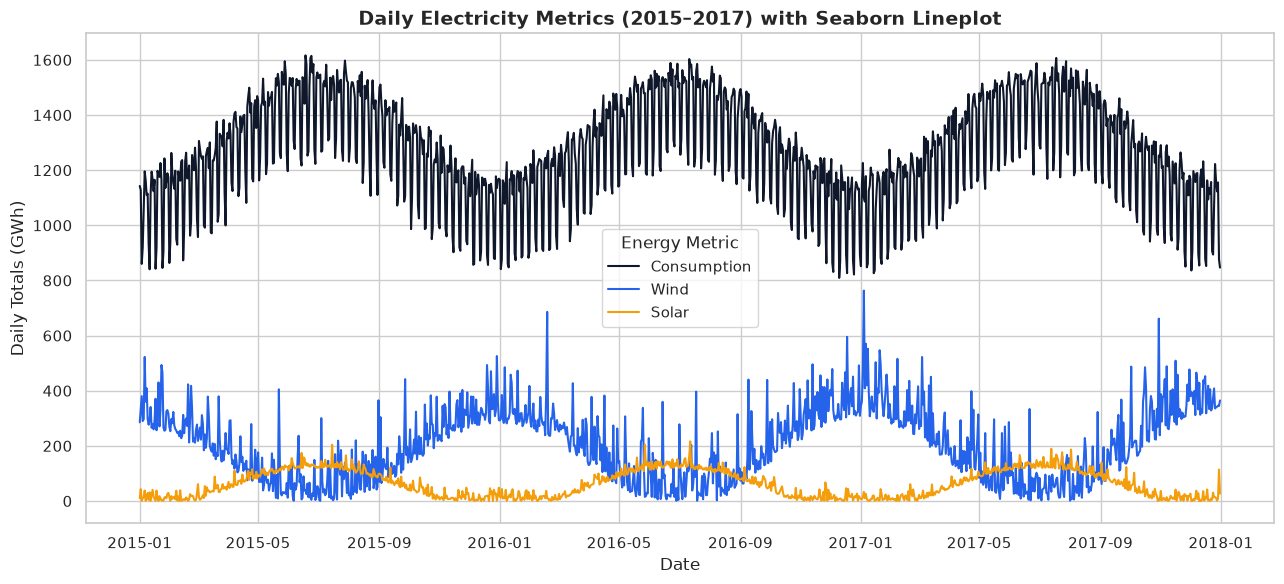

In [11]:
# Subset recent years and melt into tidy format
recent_opsd = opsd.loc['2015':'2017', ['Consumption', 'Wind', 'Solar']].reset_index()

tidy_opsd = pd.melt(
    recent_opsd,
    id_vars=['Date'],
    value_vars=['Consumption', 'Wind', 'Solar'],
    var_name='Energy_Source',
    value_name='GWh'
)

print("Tidy DataFrame Preview:")
display(tidy_opsd.head(6))

# Plot multi-series using sns.lineplot with hue and custom palette
plt.figure(figsize=(13, 6))
palette = {'Consumption': '#0F172A', 'Wind': '#2563EB', 'Solar': '#F59E0B'}

sns.lineplot(
    data=tidy_opsd,
    x='Date',
    y='GWh',
    hue='Energy_Source',
    palette=palette,
    linewidth=1.5
)

plt.title("Daily Electricity Metrics (2015–2017) with Seaborn Lineplot", fontsize=14, fontweight='bold')
plt.xlabel("Date", fontsize=12)
plt.ylabel("Daily Totals (GWh)", fontsize=12)
plt.legend(title="Energy Metric", frameon=True)
plt.tight_layout()
plt.show()


---
### Section 10: CIS 186 Student Lab Exercises
Try these hands-on challenges to test your understanding:

1. **Challenge 1 (Slicing):** Query the dataset to find the date with the highest single-day electricity consumption during the 2012 winter cold snap.
2. **Challenge 2 (Resampling):** Resample `opsd[data_cols]` to Annual frequency (`'YE'` / `'A'`) using `.sum()`. Calculate the percentage share of renewables: `(Wind + Solar) / Consumption * 100` for each year from 2012 to 2017.
3. **Challenge 3 (Visualization):** Create an `sns.barplot` showing the growth of the annual renewable percentage over time.


In [12]:
# Solution Scratchpad for Challenge 2:
# annual_totals = opsd[data_cols].resample('YE').sum(min_count=350)
# annual_totals['Renewable_Share_Pct'] = (annual_totals['Wind+Solar'] / annual_totals['Consumption']) * 100
# display(annual_totals[['Consumption', 'Wind+Solar', 'Renewable_Share_Pct']].dropna())


---
### Solution: Challenge 1 (Slicing) — Peak Consumption in the 2012 Winter Cold Snap

**Approach:**
1. Isolate the winter window with a partial-string range slice: `opsd.loc['2012-01-01':'2012-03-31']`.
2. Use `.idxmax()` on the `Consumption` column to return the timestamp of the maximum value (no manual loop needed).
3. Display a few surrounding days for context, using `pd.Timedelta` to offset the peak date.

In [13]:
# Challenge 1: Find the date with the highest single-day consumption in winter 2012
winter_2012 = opsd.loc['2012-01-01':'2012-03-31', 'Consumption']

peak_date = winter_2012.idxmax()
peak_value = winter_2012.max()

print(f"Winter window: 2012-01-01 to 2012-03-31 ({len(winter_2012)} days observed)")
print(f"Peak consumption date: {peak_date:%Y-%m-%d} ({peak_date:%A})")
print(f"Peak consumption: {peak_value:.3f} GWh")

# Show 3 days of context on either side of the peak
context = opsd.loc[
    peak_date - pd.Timedelta(days=3):peak_date + pd.Timedelta(days=3),
    ['Consumption', 'Weekday_Name', 'Is_Weekend']
]
print("\nSurrounding days:")
display(context)

Winter window: 2012-01-01 to 2012-03-31 (91 days observed)
Peak consumption date: 2012-03-28 (Wednesday)
Peak consumption: 1361.930 GWh

Surrounding days:


,Consumption,Weekday_Name,Is_Weekend
Date,,,
2012-03-25,1010.321,Sunday,True
2012-03-26,1355.526,Monday,False
2012-03-27,1294.969,Tuesday,False
2012-03-28,1361.930,Wednesday,False
2012-03-29,1358.237,Thursday,False
2012-03-30,1285.082,Friday,False
2012-03-31,1045.210,Saturday,True


---
### Solution: Challenge 2 (Resampling) — Annual Renewable Share (2012–2017)

**Approach:**
1. Resample the daily energy columns to year-end frequency with `.resample('YE').sum(min_count=350)`. The `min_count` guard prevents sparse or partial years from collapsing to `0`.
2. Compute the renewable percentage share: `(Wind + Solar) / Consumption * 100`.
3. Slice the annual table down to 2012–2017 — the period where both `Wind` and `Solar` have (nearly) complete coverage.

In [14]:
# Challenge 2: Annual totals and renewable share of consumption (2012-2017)
annual_totals = opsd[data_cols].resample('YE').sum(min_count=350)
annual_totals['Renewable_Share_Pct'] = (annual_totals['Wind+Solar'] / annual_totals['Consumption']) * 100

renewable_share = annual_totals.loc['2012':'2017', ['Consumption', 'Wind+Solar', 'Renewable_Share_Pct']]
display(renewable_share.round(2))

,Consumption,Wind+Solar,Renewable_Share_Pct
Date,,,
2012-12-31,464899.23,77392.77,16.65
2013-12-31,463954.64,80603.53,17.37
2014-12-31,463254.57,89070.72,19.23
2015-12-31,464068.78,92702.03,19.98
2016-12-31,463761.56,98940.04,21.33
2017-12-31,462253.47,104128.01,22.53


---
### Solution: Challenge 3 (Visualization) — Growth of the Annual Renewable Share

**Approach:**
1. Reset the annual index so `Date` becomes a regular column, then derive a numeric `Year` label for the x-axis.
2. Feed the tidy frame to `sns.barplot`, mapping year to the x-axis and renewable percentage to the y-axis.
3. Annotate each bar with its exact percentage using `ax.bar_label` for easy reading.

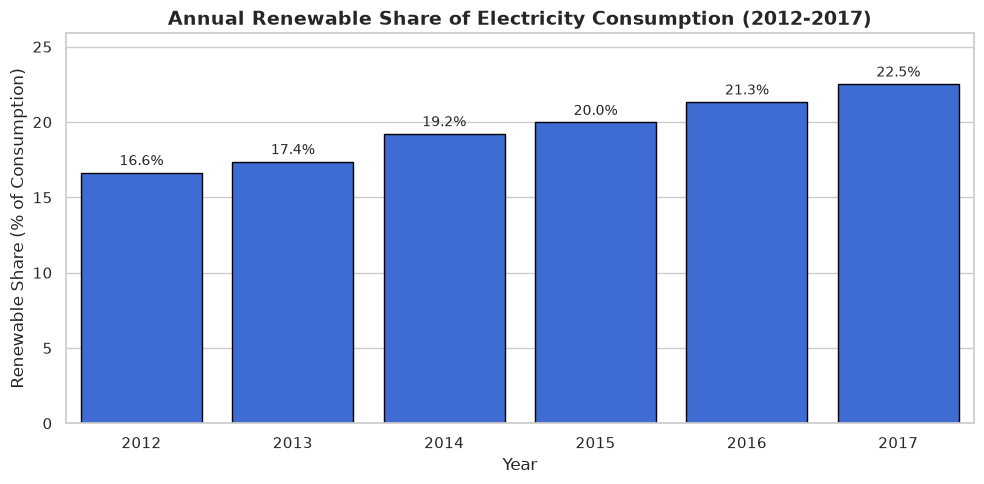

In [15]:
# Challenge 3: Barplot of annual renewable share growth (2012-2017)
plot_df = renewable_share.reset_index()
plot_df['Year'] = plot_df['Date'].dt.year

plt.figure(figsize=(10, 5))
ax = sns.barplot(
    data=plot_df,
    x='Year',
    y='Renewable_Share_Pct',
    color='#2563EB',
    edgecolor='black'
)
ax.bar_label(ax.containers[0], fmt='%.1f%%', padding=3, fontsize=10)

plt.title('Annual Renewable Share of Electricity Consumption (2012-2017)', fontsize=14, fontweight='bold')
plt.xlabel('Year', fontsize=12)
plt.ylabel('Renewable Share (% of Consumption)', fontsize=12)
plt.ylim(0, plot_df['Renewable_Share_Pct'].max() * 1.15)
plt.tight_layout()
plt.show()